In [5]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ppghr.data import ACTIVITY_NAMES, PROCESSED_DIR, PROJECT_DIR
from ppghr.baseline import estimate_hr_fft
from ppghr.windows import load_all_windows

summary = json.load(open(PROJECT_DIR / "results" / "step8_summary.json"))
saved = np.load(PROCESSED_DIR.parent / "step8_predictions.npz")

print(f"Honest (nested) leave-one-subject-out MAE: {summary['nested_loso_mae']} bpm")
print(f"Within 5 bpm: {summary['within_5_bpm_percent']}% of windows")
pd.DataFrame(summary["exploration_loso_300_trees"]).T

Honest (nested) leave-one-subject-out MAE: 7.54 bpm
Within 5 bpm: 61.5% of windows


,plain,snapped
spectra + peaks,8.82,8.70
+ peak history,7.97,7.80
+ averages,7.71,7.53


In [6]:
choices = pd.DataFrame(summary["nested_choices"]).T
choices["MAE (bpm)"] = pd.Series(summary["nested_per_subject_mae"])
choices

,features,trees,snap,MAE (bpm)
S1,+ averages,1000,10,6.90
S2,+ averages,1000,10,5.25
S3,+ averages,1000,10,4.08
S4,+ averages,1000,10,6.46
S5,+ peak history,1000,10,20.80
S6,+ averages,1000,10,7.77
S7,+ averages,1000,10,3.93
S8,+ averages,1000,10,11.63
S9,+ averages,1000,10,8.19
S10,+ averages,1000,10,4.49


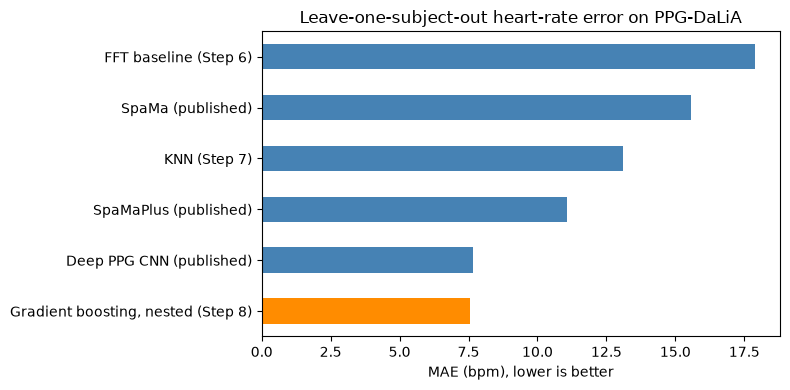

In [7]:
scores = pd.Series({
    "FFT baseline (Step 6)": 17.9,
    "SpaMa (published)": 15.56,
    "KNN (Step 7)": 13.1,
    "SpaMaPlus (published)": 11.06,
    "Deep PPG CNN (published)": 7.65,
    "Gradient boosting, nested (Step 8)": summary["nested_loso_mae"],
}).sort_values()
colors = ["darkorange" if "Step 8" in name else "steelblue" for name in scores.index]
scores.plot.barh(figsize=(8, 4), color=colors)
plt.xlabel("MAE (bpm), lower is better")
plt.title("Leave-one-subject-out heart-rate error on PPG-DaLiA")
plt.tight_layout()
plt.show()

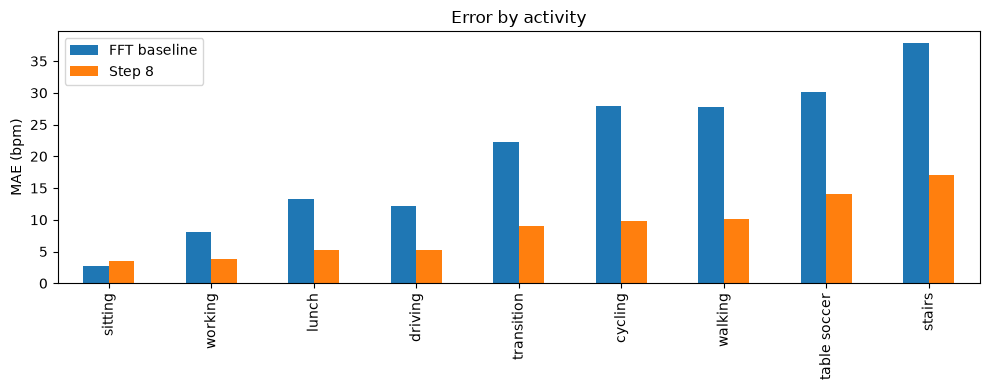

,FFT baseline,Step 8
sitting,2.7,3.5
working,8.0,3.8
lunch,13.2,5.2
driving,12.2,5.3
transition,22.2,9.1
cycling,27.9,9.8
walking,27.8,10.2
table soccer,30.2,14.0
stairs,37.8,17.0


In [8]:
data = load_all_windows()
baseline_error = np.abs(estimate_hr_fft(data["ppg"]) - data["hr"])
step8_error = np.abs(saved["predictions"] - saved["hr"])
by_activity = pd.DataFrame({
    "FFT baseline": pd.Series(baseline_error).groupby(saved["activity"]).mean(),
    "Step 8": pd.Series(step8_error).groupby(saved["activity"]).mean(),
}).rename(index=ACTIVITY_NAMES).round(1).sort_values("Step 8")
by_activity.plot.bar(figsize=(10, 4))
plt.ylabel("MAE (bpm)")
plt.title("Error by activity")
plt.tight_layout()
plt.show()
by_activity